## Implementation of Otsu's Segmentation and Morphological Operations

This notebook contains the custom implementation for:
- **Otsu's Thresholding Segmentation**
- **Morphological Operations** (Dilation, Erosion, Opening, Closing)
- **Comparison analysis** between segmentation results with and without morphological operations.

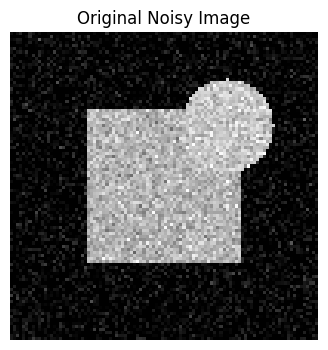

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create a synthetic binary image with some noise to demonstrate segmentation and morphology
def create_synthetic_image():
    # Generate a background
    img = np.zeros((100, 100), dtype=np.uint8)
    # Draw a rectangle
    img[25:75, 25:75] = 180
    # Draw a circle
    y, x = np.ogrid[:100, :100]
    mask = (x - 70)**2 + (y - 30)**2 <= 15**2
    img[mask] = 200

    # Add random Gaussian noise
    np.random.seed(42)
    noise = np.random.normal(0, 25, img.shape).astype(np.int16)
    noisy_img = np.clip(img + noise, 0, 255).astype(np.uint8)
    return noisy_img

# Generate and display original noisy image
image = create_synthetic_image()
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap='gray')
plt.title("Original Noisy Image")
plt.axis('off')
plt.show()

### 1. Otsu's Threshold Segmentation from Scratch

In [ ]:
def otsu_threshold(img):
    # Calculate histogram
    hist, bins = np.histogram(img.flatten(), bins=256, range=[0, 256])
    total_pixels = img.size

    current_max = -1
    threshold = 0

    # Auxiliary sum variables to speed up calculation
    sum_total = np.dot(np.arange(256), hist)
    sum_background = 0
    weight_background = 0

    for t in range(256):
        weight_background += hist[t]
        if weight_background == 0:
            continue

        weight_foreground = total_pixels - weight_background
        if weight_foreground == 0:
            break

        sum_background += t * hist[t]

        mean_background = sum_background / weight_background
        mean_foreground = (sum_total - sum_background) / weight_foreground

        # Between-class variance
        var_between = weight_background * weight_foreground * (mean_background - mean_foreground) ** 2

        if var_between > current_max:
            current_max = var_between
            threshold = t

    return threshold

def apply_threshold(img, thresh):
    binary = np.zeros_like(img)
    binary[img >= thresh] = 1
    return binary

# Compute Otsu's threshold
otsu_val = otsu_threshold(image)
segmented_none = apply_threshold(image, otsu_val)

print(f"Otsu's calculated threshold: {otsu_val}")

Otsu's calculated threshold: 96


### 2. Morphological Operations from Scratch
Using a standard 3x3 square structuring element (kernel) for the operations.

In [ ]:
def pad_image(binary_img, pad_size=1):
    return np.pad(binary_img, pad_size, mode='constant', constant_values=0)

def custom_dilation(binary_img):
    padded = pad_image(binary_img, 1)
    dilated = np.zeros_like(binary_img)

    # Iterate through the image pixels
    for r in range(binary_img.shape[0]):
        for c in range(binary_img.shape[1]):
            # Extract 3x3 neighborhood
            neighborhood = padded[r:r+3, c:c+3]
            # If any pixel in structuring element is 1, set center to 1
            if np.any(neighborhood == 1):
                dilated[r, c] = 1
    return dilated

def custom_erosion(binary_img):
    padded = pad_image(binary_img, 1)
    eroded = np.zeros_like(binary_img)

    # Iterate through the image pixels
    for r in range(binary_img.shape[0]):
        for c in range(binary_img.shape[1]):
            # Extract 3x3 neighborhood
            neighborhood = padded[r:r+3, c:c+3]
            # All pixels in neighborhood must be 1 to keep center 1
            if np.all(neighborhood == 1):
                eroded[r, c] = 1
    return eroded

def custom_opening(binary_img):
    # Opening is erosion followed by dilation
    return custom_dilation(custom_erosion(binary_img))

def custom_closing(binary_img):
    # Closing is dilation followed by erosion
    return custom_erosion(custom_dilation(binary_img))

### 3. Comparison and Visualization
Applying all operations to our Otsu segmented image and plot the comparison side-by-side.

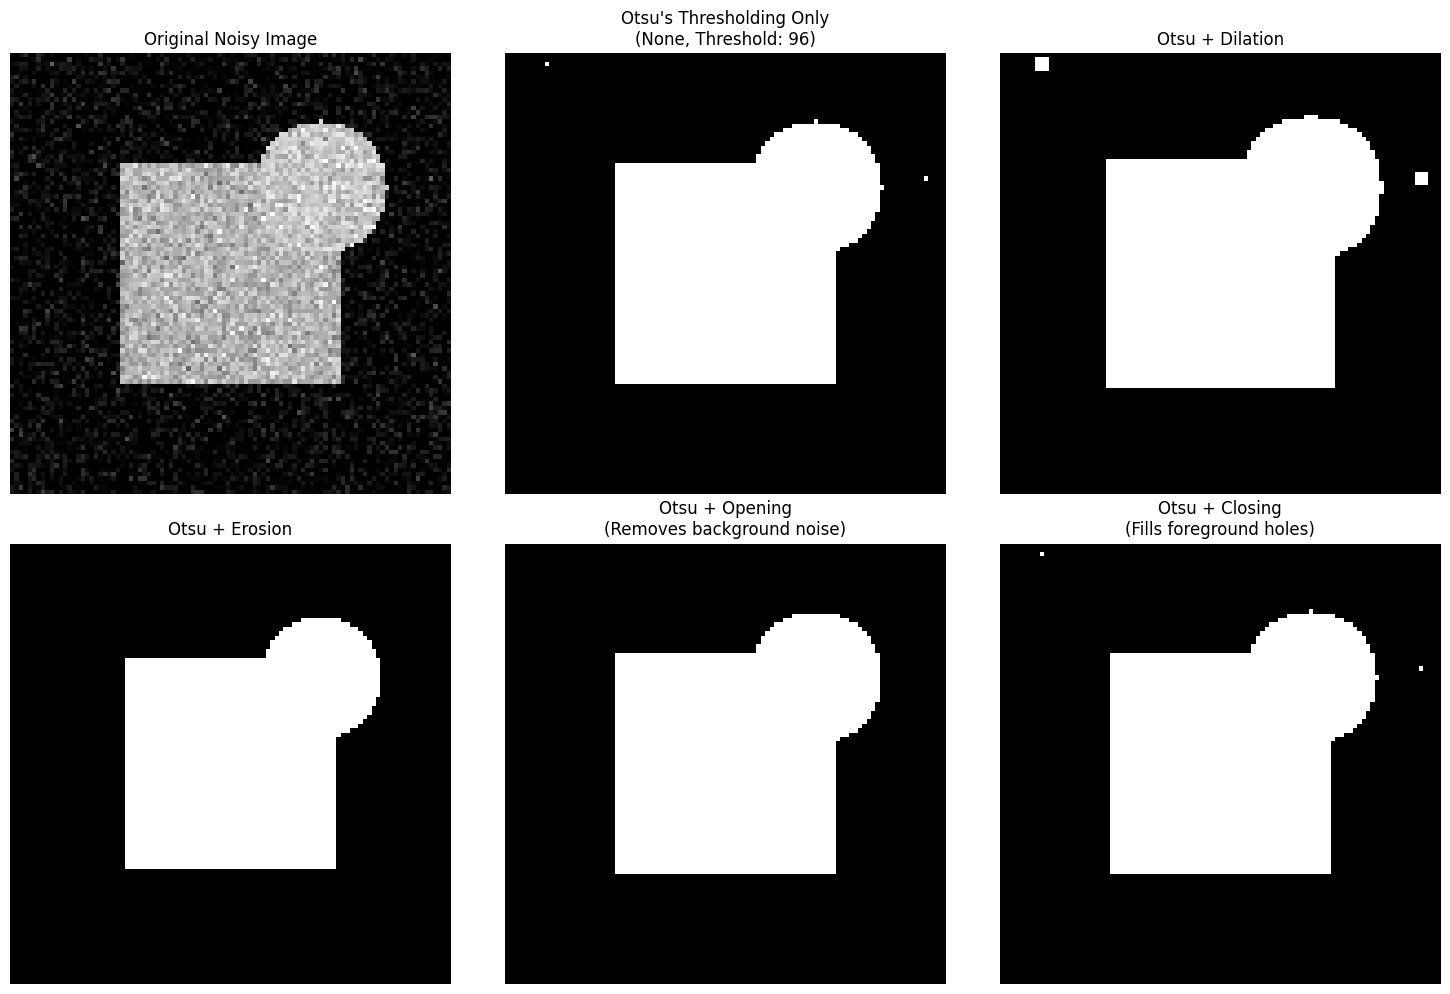

In [ ]:
# Apply custom morphology operations
segmented_dilation = custom_dilation(segmented_none)
segmented_erosion = custom_erosion(segmented_none)
segmented_opening = custom_opening(segmented_none)
segmented_closing = custom_closing(segmented_none)

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(image, cmap='gray')
axes[0, 0].set_title("Original Noisy Image")
axes[0, 0].axis('off')

axes[0, 1].imshow(segmented_none, cmap='gray')
axes[0, 1].set_title(f"Otsu's Thresholding Only\n(None, Threshold: {otsu_val})")
axes[0, 1].axis('off')

axes[0, 2].imshow(segmented_dilation, cmap='gray')
axes[0, 2].set_title("Otsu + Dilation")
axes[0, 2].axis('off')

axes[1, 0].imshow(segmented_erosion, cmap='gray')
axes[1, 0].set_title("Otsu + Erosion")
axes[1, 0].axis('off')

axes[1, 1].imshow(segmented_opening, cmap='gray')
axes[1, 1].set_title("Otsu + Opening\n(Removes background noise)")
axes[1, 1].axis('off')

axes[1, 2].imshow(segmented_closing, cmap='gray')
axes[1, 2].set_title("Otsu + Closing\n(Fills foreground holes)")
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()